# Which information belongs to a forecast at issuance?

**Question:** How can the same electricity excerpt yield a different historical method choice, final-block ranking, and interval coverage trajectory?

## Objectives

A dashboard can show a preferred method, a path for a particular forecast origin and a recent coverage estimate on one screen. They use different observations and answer different questions. We will reproduce these quantities while tracking the information available to each calculation. The same experiment also shows how a small teaching export differs from a complete product release.

The test case is a chronological excerpt of meter MT_010 in the UCI electricity collection. Its hourly values are sums of the retained quarter-hour measurements. We reserve the final 24 observations of a five-day excerpt for one forecast and use earlier observations for the historical scores. The rolling backtest, the later reserved forecast and the one-step replay use the same source but use different origins. None represents a new customer planning result. We will keep their numerical outputs separate even when they have the same method name.

## Setup

Use the declared notebook runtime. The stage registry discovers optional adapters from the installed libraries, so the roster can differ from the full published offline roster. The notebook prints the roster it actually executes. There is no checkpoint download in this environment. Exact pins make both the local methods and their reference packages identifiable.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
```


In [1]:
# Initialize the pinned numerical environment without downloading input data.
from pathlib import Path
import importlib.metadata
import json
import sys
from tempfile import TemporaryDirectory
from time import perf_counter
import warnings
import numpy as np
import matplotlib.pyplot as plt
from preqts import SeasonalNaive
root = next(path for path in Path.cwd().parents if (path / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab import registry
from chronoscopelab.core.manifest import build_index
from chronoscopelab.io.formats import write_json
from chronoscopelab.io.schema import SeriesSpec
from chronoscopelab.model.forecasters import classical_forecasters, forecast_all
from chronoscopelab.reevaluation import metrics
from chronoscopelab.stages import analyze, evaluate, export, feature_extraction, infer, preprocess, streaming, train
plt.rcParams.update({"figure.figsize": (8, 3.2), "figure.dpi": 95, "font.size": 10})
print("PreqTS", importlib.metadata.version("preqts"))


PreqTS 0.3.0


## Data

The ingestion stage reads a long table whose keys are series identity and timestamp. It returns accepted records, rejected records and warnings. The warning mechanism distinguishes a suspicious observation from an unreadable or inadmissible series. An accepted record can still have missing values under the ingestion rule. Additional conditions are needed before a model consumes a contiguous finite prefix. In this example the slice is contiguous and finite. We cut the slice in timestamp order and keep the original positions, so a seasonal lag of 24 refers to one day.


In [2]:
# Admit the long-format source and take a contiguous chronological excerpt.
table = preprocess.run(str(root / "data/examples/electricity_sample.csv"))
case = registry.get_case("REAL_electricity")
record = table.accepted[0]
spec = SeriesSpec(case.id, tuple(record.y[:120]), 24, case.horizon, "H", case.source)
levels = (0.1, 0.5, 0.9)
prefix, target = infer.split(spec)
fitting = SeriesSpec(case.id, tuple(prefix), spec.seasonality, spec.horizon, "H", case.source)
print("Ingestion", table.summary())
print("Series, fitting rows, reserved rows:", record.unique_id, len(prefix), len(target))


Ingestion 1 accepted, 0 rejected, 0 flagged
Series, fitting rows, reserved rows: MT_010 96 24


The code starts with a single source record and defines the horizon before calling any scoring function. The inference stage reserves the last block, fits on the preceding prefix and returns predictions. The targets are passed only to the scoring and export steps. The same separation also applies to diagnostics when they inform a decision. A retrospective graph may use the whole series to explain what happened. A diagnostic used to choose a forecast must be calculated using the information already available at issuance.

## Method

Call the feature stage and diagnostic stage on the fitting prefix. The feature row records familiar quantities such as lag-one correlation in a compact form. It describes the data supplied to it and does not predict the next observation. The larger analysis record adds separate panels whose applicability can vary. Some diagnostics remove nonfinite observations or require optional dependencies. A panel with an error or skip record needs to be read as unavailable. The code prints panel identities to make the boundary visible without interpreting every statistic as a conclusion about this meter.


In [3]:
# Pass only the fitting prefix into the diagnostic and feature stages.
with warnings.catch_warnings(record=True):
    warnings.simplefilter("always")
    features = feature_extraction.run(fitting)
    analysis = analyze.run(fitting, seed=42)
print("Mean and lag-one correlation:", round(features.mean, 4), round(features.acf1, 4))
print("Analyzed panels:", ", ".join(sorted(analysis)))


Mean and lag-one correlation: 282.9973 0.8825
Analyzed panels: autocorrelation, causality, changepoints, distribution, filters, fractal, n, nonlinear, seasonality, seasonality_period, sequence, stationarity, volatility


A point prediction from the final origin can be compared with a reserved value at the same lead. Let $n$ be the prefix length, $h$ the horizon and $m$ the seasonal lag. Compute the historical scale once using only the prefix.

$$
s_m=\frac{1}{n-m}\sum_{i=m+1}^{n}|y_i-y_{i-m}|.
$$

The final-block MASE for a point path $\widehat y$ is

$$
\operatorname{MASE}=\frac{1}{h s_m}\sum_{j=1}^{h}|y_{n+j}-\widehat y_{n+j}|.
$$

The denominator measures past variation relative to seasonal recurrence. A small value can amplify errors even when their absolute size is modest. The code uses the same prefix scale for all final paths, which makes their scores directly comparable on this origin. The historical evaluator constructs its own prequential scale for a different set of earlier origins. Comparing the rankings is meaningful as a diagnostic of sensitivity to evaluation design; a difference between the scores is not an estimate of degradation measured on repeated independent blocks.

## Comparison

The package reference repeats the last daily phase and returns three quantile columns. Its median equals the recorded value at the corresponding phase for these 24 leads. The Theta path comes from the installed ChronoScope inference stage. The ribbon belongs to that path's lower and upper quantiles, and the actual line is drawn only after fitting. Compare the lines during the rising and falling portions of the day. An average error can hide a peak shift or a failure to respond to a downward ramp.


Available adapters: SeasonalNaive, SES, Holt, HoltWinters, Theta, AutoETS, AutoTheta, AutoARIMA, LightGBM, ContextMemory
Numerical warning types: ['TqdmWarning', 'UserWarning']


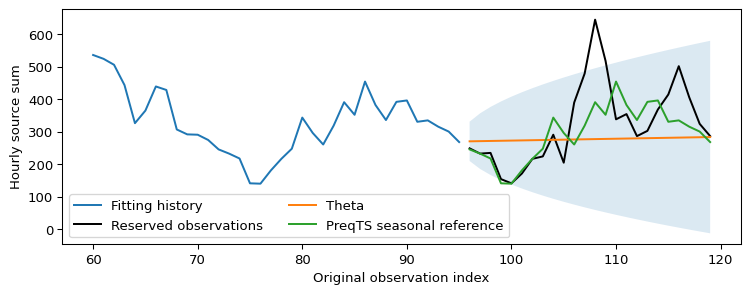

In [4]:
# Issue final-block predictions, then call a package reference at the same origin.
with warnings.catch_warnings(record=True) as notices:
    warnings.simplefilter("always")
    forecast = infer.run(spec, levels)
print("Available adapters:", ", ".join(row.name for row in forecast.methods))
print("Numerical warning types:", sorted({type(w.message).__name__ for w in notices}))
theta = next(method for method in forecast.methods if method.name == "Theta")
reference = SeasonalNaive(seasonality=spec.seasonality)
reference.start(np.asarray(prefix))
ref = np.asarray(reference.predict(spec.horizon, list(levels)))
assert np.array_equal(ref[:, 1], prefix[-spec.seasonality:][:spec.horizon])
fig, ax = plt.subplots()
indices = np.arange(len(prefix), len(spec.y))
ax.plot(np.arange(len(prefix))[-36:], prefix[-36:], label="Fitting history")
ax.plot(indices, target, color="black", label="Reserved observations")
ax.plot(indices, theta.point, label="Theta")
ax.plot(indices, ref[:, 1], label="PreqTS seasonal reference")
ax.fill_between(indices, theta.lower, theta.upper, alpha=0.16)
ax.set(xlabel="Original observation index", ylabel="Hourly source sum")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()


The next figure pairs rolling and final-block scores for SeasonalNaive, SES, Holt, HoltWinters and Theta. The rolling evaluator fits earlier forecast origins in the prefix and scores the corresponding later blocks there. Candidate adapters may have different historical window budgets, so the figure compares only these five implementations. For each of them the single final block has one particular pattern of targets. A method with low error over earlier origins may encounter a different daily level or phase in the reserved block. Check which method has the smallest bar within each evaluation and report the origin design with that ranking.


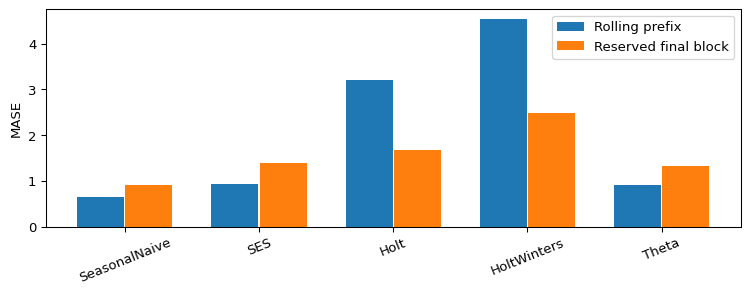

Rolling selection: SeasonalNaive


In [5]:
# Keep rolling prefix scores distinct from errors on the common final block.
historical = evaluate.run(spec, levels, classical_forecasters())
eligible = [row for row in forecast.methods if row.name in historical["methods"]]
final = [metrics(prefix, target, row.point, row.lower, row.upper, spec.seasonality)["mase"]
         for row in eligible]
fig, ax = plt.subplots()
positions = np.arange(len(eligible))
ax.bar(positions - 0.18, [historical["methods"][row.name]["mase"] for row in eligible],
       width=0.35, label="Rolling prefix")
ax.bar(positions + 0.18, final, width=0.35, label="Reserved final block")
ax.set_xticks(positions, [row.name for row in eligible], rotation=22)
ax.set(ylabel="MASE")
ax.legend()
fig.tight_layout()
plt.show()
print("Rolling selection:", historical["best_method"])


### Sensitivity to the evaluation window

A separate one-step replay now stays inside the same fitting history. On each replay step the forecaster predicts before seeing the next outcome. The controller can change its next interval after learning whether the current one covered the realized value. This information order gives an adaptive interval a well-defined meaning. It does not make predictions at neighboring times statistically independent. The historical score table and the coverage trajectory also have different horizons, so no coverage claim for the 24-step band follows from this calculation.


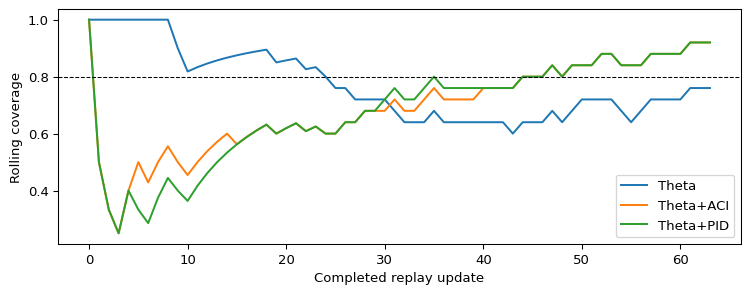

In [6]:
# Run an independent one-step replay inside the fitting history.
replay = streaming.run(fitting)
fig, ax = plt.subplots()
for name in ("Theta", "Theta+ACI", "Theta+PID"):
    row = replay["methods"][name]
    ax.plot(row["rolling_coverage"], label=name)
ax.axhline(replay["nominal_coverage"], linestyle="--", color="black", linewidth=0.8)
ax.set(xlabel="Completed replay update", ylabel="Rolling coverage")
ax.legend()
fig.tight_layout()
plt.show()


The dashed line is the declared marginal target. When a curve approaches it, inspect how long the nearby values persist and what happened earlier. A high coverage level alone can be obtained with a wide interval. A low score under a proper interval metric requires balancing width and missed observations. The plotted trajectories do not supply uncertainty on a future coverage fraction. They let a reader see, on this particular prefix, when a controller responds to a sequence of misses. The one-step wrapper refits its base forecast on available history; the elapsed time of that wrapper is different from the time to update an estimator with persistent native state.

## Results

**Answer:** The rolling ranking summarizes earlier forecast origins inside the 96 available observations. The final ranking uses the 24 reserved observations, and the coverage graph uses one-step updates inside the prefix. These quantities differ when the sampled origins, horizons, and available observations differ. Read each evaluation with its own denominator and target window.

The training selector in the next cell uses two generated histories. It averages the rolling MASE for each of the same five forecasters across those histories and records a default. The choice is neither derived from the electricity targets nor used to select the electricity winner. The export stage writes a trace, manifest, analysis and replay to a temporary directory. It records the measured cost of the five-adapter forecast call for this run, but no machine-specific timing is printed as a reproducible result. The manifest supplies an artifact path and byte count, and the index names which manifest belongs to each case. The code checks this relation before the directory is removed.


In [7]:
# Train on distinct generated histories and write a disposable artifact and index.
training = [registry.build_series(registry.get_case(name), seed=42)
            for name in ("TRND_seasonal", "SEAS_hourly")]
start = perf_counter()
forecast_all(prefix, spec.seasonality, spec.horizon, levels)
elapsed_ms = (perf_counter() - start) * 1000
with TemporaryDirectory() as directory:
    output = Path(directory)
    selector = train.run(training, str(output / "models"), levels)
    manifest = export.run(case=case, feature=features, result=forecast, actual=target.tolist(),
                          eval_metrics=historical, seed=42, run_ms=elapsed_ms, flags=table.flagged,
                          derived_dir=directory, manifests_dir=str(output / "manifests"),
                          analysis=analysis, streaming_bench=replay)
    path = output / manifest["artifact"]["path"]
    assert path.stat().st_size == manifest["artifact"]["bytes"]
    trace = json.loads(path.read_text(encoding="utf-8"))
    assert trace["history_len"] == len(prefix) and trace["horizon"] == len(target)
    index = build_index([{"case_id": case.id, "category": case.category,
                          "manifest_path": f"manifests/{case.id}.json"}])
    write_json(output / "manifests/index.json", index)
print("Disposable index size:", index["n_cases"],
      "training default:", selector["default_method"])


Disposable index size: 1 training default: HoltWinters


The release inventory uses the same general file relationships across the entire product. A single well-formed trace does not show that an application has every case or evidence file it declares. The readiness record names the current catalog digest and version, and the admitted index records the full case count. Schema checks, exact numerical bindings and complete cohort checks accompany readiness. Read the recorded inventory and identities separately from the small training exercise.


In [8]:
# Read the case and contract counts in the complete release inventory.
current = json.loads((root / "data/derived/readiness.json").read_text(encoding="utf-8"))
admitted = json.loads((root / "data/derived/manifests/index.json").read_text(encoding="utf-8"))
print("Committed index size:", admitted["n_cases"], "readiness entries:", len(current["contracts"]))
print("Catalog checksum:", current["catalog_sha256"],
      "product version:", current["product_version"])


Committed index size: 15 readiness entries: 15
Catalog checksum: 867d58642d93ad3df83ee1b29207549f2ccafb0050291995f92332d9b17477e8 product version: 0.25.000


### Identify the origin behind a published score

The full fresh comparison has an electricity row with the same case label and horizon. It uses the final block of the complete admitted history. The local teaching cut uses an earlier day, so equal case labels and horizons cannot establish equal targets. Compare the lengths and targets before transferring a score. The independent combination study has a second level of identity. Its index points to a specific source series, and its case record contains the eligible origins with fitting-prefix digests, scales, targets and all forecast paths. Follow one index entry below and interpret the shape of its first ValidationMix path as reserved observations by quantile levels. The compact index serves navigation. The case record supplies the information needed to inspect a numerical claim about that series.


In [9]:
# Identify the different evaluation origins before comparing recorded scores.
derived = root / "data/derived"
fresh = json.loads((derived / "fresh-reevaluation.json").read_text(encoding="utf-8"))
released = next(row for row in fresh["cases"] if row["case_id"] == case.id)
combination_index = json.loads((derived / "validated-combinations.json").read_text(encoding="utf-8"))
entry = next(row for row in combination_index["cases"]
             if (row["dataset"], row["id"]) == ("m4_weekly", "T1"))
combination_case = json.loads((derived / entry["path"]).read_text(encoding="utf-8"))
first = combination_case["origins"][0]
mix = next(method for method in first["methods"] if method["name"] == "ValidationMix")
print("Released electricity fitting length:", released["history_length"])
print("Electricity teaching and published first targets:", target[0], released["actual"][0])
print("External series, first cutoff, reserved length:", entry["id"], first["origin"], len(first["actual"]))
print("ValidationMix path shape:", np.asarray(mix["quantiles"]).shape)


Released electricity fitting length: 456
Electricity teaching and published first targets: 248.3871 237.6344
External series, first cutoff, reserved length: T1 2153 13
ValidationMix path shape: (13, 3)


The browser experiment uses a different boundary again. Its frozen linear graph accepts a fixed-length normalized prefix and produces twelve point values. The original ridge study changed the point estimator, while the confirmation study keeps the graph and points fixed and changes only the prediction intervals. Rescore the retained studies before comparing the normalized errors. The independent checker verifies the graph digest, configuration identities, split separation and arithmetic on retained forecast paths. This calculation uses their retained outputs; it does not refit the graph or measure new browser runtime.


In [10]:
# Rescore two admitted studies before interpreting browser interval changes.
sys.path.insert(0, str(root / "scripts"))
from check_browser_linear_evidence import validate
validated = validate(root)
print("Independently rescored studies:", [study["study"] for study in validated])
browser = root / "docs/research/browser-linear"
ridge = json.loads((browser / "v1/results.json").read_text(encoding="utf-8"))["scores"]["all"]
confirmed = json.loads((browser / "confirmation-v1/results.json").read_text(encoding="utf-8"))["scores"]["all"]
metadata = json.loads((root / "frontend/public/models/nlinear.json").read_text(encoding="utf-8"))
print("Frozen graph lookback and horizon:", metadata["lookback"], metadata["horizon"])
print("Point MAE, frozen and ridge:", [round(row["normalized_mae"], 4) for row in ridge.values()])
print("Confirmation interval scores:", {name: round(row["normalized_interval_score"], 4)
                                         for name, row in confirmed.items()})


Independently rescored studies: ['v1', 'confirmation-v1']
Frozen graph lookback and horizon: 48 12
Point MAE, frozen and ridge: [0.5141, 0.518, 1.0645]
Confirmation interval scores: {'gaussian': 4.749, 'global': 2.8038, 'stratified': 2.3934}


In the ridge comparison, first compare point MAE against the frozen model. A narrower interval can improve an interval score even if the center becomes worse. In the confirmation, compare interval scores for the same point path. The calibration group depends on roughness within the observed prefix. Its empirical residual radii come from separate calibration series, and the score is measured on untouched generated test series. A normalized score is expressed relative to the prefix scale. It cannot be read as an electricity-unit error, and the synthetic test cannot establish real-data coverage for the teaching meter.

### Repeat the comparison with your own data

Choose a horizon that corresponds to an action such as staffing the next shift. Preserve timestamps and sampling frequency, including daylight-saving transitions. Record the policy for gaps and repeated times before ingesting the table. Use separate histories for training a default where available. Pick final evaluation blocks before scoring, keep the fitting prefix contiguous, and decide whether a controller can see outcomes immediately or only after a delay. Make the same assumption for each compared method.

Inspect the two scoring designs with several consecutive reserved days if enough history is available. Keep each day's entire path, its method revision and its units. If an adapter cannot forecast an origin, report the failure and analyze the common-support results explicitly. Retain available long-format records and versioned hashes so a reader can recover which observations supported every result. Before publishing an export, verify redistribution rights for the original series and inspect whether the per-step forecast or diagnostic arrays reveal restricted values.

## Summary

Identify the origins and information sets first. Choose a score appropriate to the decision horizon, preserve all forecasts and targets, and document the training histories and available methods. A trace and manifest let a reader inspect these choices, while completeness and evidence checks determine whether a whole research release is ready.

## References

- [UCI electricity source](https://doi.org/10.24432/C58C86).
- [Dawid's prequential framework](https://doi.org/10.2307/2981683).
- [Adaptive conformal inference](https://arxiv.org/abs/2106.00170).
- [PreqTS 0.3.0](https://pypi.org/project/preqts/0.3.0/).
